# Biểu đồ so sánh các bộ 30 tuyến

Đọc M0 có sẵn để xem phân bố D và quan hệ D với độ phủ/chiều dài. **Python thường**, không cần PyQGIS. Notebook này không bốc lại mẫu hoặc chọn lại tuyến; dùng [notebook 10](10_random_baseline.ipynb) cho việc đó.

[Hướng dẫn và cách diễn giải](../docs/lez/RANDOM_COMPARISON_PLOTS.md). Chạy từ trên xuống; hai hình và bảng sẽ được xuất ở cell cuối.

In [1]:
from pathlib import Path
import importlib
import importlib.util
import os
import sys
import tempfile

WORK = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / "scripts/lez/selection_plots.py").is_file()), None)
if WORK is None:
    raise RuntimeError("Mở notebook từ thư mục work hoặc work/notebooks.")
missing = [name for name in ("numpy", "pandas", "matplotlib", "seaborn")
           if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError("Kernel thiếu: " + ", ".join(missing)
                       + ". Chọn Python có các thư viện trong requirements-notebook.txt.")
cache = Path(tempfile.gettempdir()) / "hanoi_work_matplotlib"
cache.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(cache))
sys.path.insert(0, str(WORK / "scripts"))
plots = importlib.import_module("lez.selection_plots")
if Path(plots.__file__).resolve() != (WORK / "scripts/lez/selection_plots.py").resolve():
    raise RuntimeError("Kernel đang giữ module từ dự án khác. Restart Kernel rồi chạy lại.")
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display
shell = get_ipython()
if shell is not None:
    shell.run_line_magic("matplotlib", "inline")
print("Đã tìm thấy thư mục work và các thư viện vẽ.")

Đã tìm thấy thư mục work và các thư viện vẽ.


### 1. Chọn nguồn và tham số

`auto` ưu tiên M0 tại máy; chỉ dùng bản công bố nếu chưa có con trỏ M0. `published` chủ động chọn bản công bố ngày 02/11/2026. Nguồn hỏng hoặc bộ gốc tại máy đã đổi sẽ báo lỗi.

Đổi tham số rồi chạy lại các cell phía dưới hoặc Run All. Khoảng D phục vụ trình bày, không phải ngưỡng đạt.

In [2]:
SOURCE = "auto"  # "auto", "latest", "published"
BIN_WIDTH = 0.02  # có thể đổi thành 0.05
HIST_STAT = "percent"  # "percent" hoặc "count"
X_METRIC = "unique_rc_coverage_fraction"  # hoặc "traversed_length_m"
FIT_LINE = True  # False: chỉ vẽ các điểm, không thêm đường hồi quy

### 2. Đọc và kiểm tra kết quả

Kiểm hash kết quả, số bộ, quota, bộ gốc và thống kê D trước khi vẽ. Đây không phải kiểm lại toàn bộ GIS hoặc bằng chứng thực địa.

In [3]:
data = plots.load_comparison(WORK, source=SOURCE)
print("Nguồn:", "M0 tại máy" if data.source == "latest" else "Bản công bố cố định 02/11/2026")
print("Fingerprint M0:", data.report["fingerprint"])
print("Thời điểm lượt M0 / ngày bản công bố:", data.report.get("finished_at", data.report.get("reviewed_on")))
print("Quota:", data.report["quota"])
print("Số bộ hợp lệ:", len(data.frame))
display(data.frame[["sample_id", "D_combined", "traversed_length_m",
                    "unique_rc_coverage_fraction"]].head())

Nguồn: M0 tại máy
Fingerprint M0: c0dab6f8b0b424a196759e275fde355644949ce572788eb176cf8428ce6ce953
Thời điểm lượt M0 / ngày bản công bố: 2026-11-02T04:37:06.124297+00:00
Quota: {'inside': 18, 'outside': 12}
Số bộ hợp lệ: 1000


,sample_id,D_combined,traversed_length_m,unique_rc_coverage_fraction
0,1,0.677850,272315.428212,0.010479
1,2,0.595221,266327.029875,0.010206
2,3,0.510428,308332.723215,0.012169
3,4,0.472314,283425.515507,0.010851
4,5,0.560074,284480.726513,0.010897


### 3. So sánh với bộ 30 đã chọn

D thấp hơn là cơ cấu chiều dài RC gần mạng tham chiếu hơn. Bộ gốc là mốc đối chiếu, không được thêm thành một bộ ngẫu nhiên. Số bộ bằng/khác mốc dùng dung sai của protocol.

In [4]:
comparison = plots.describe_comparison(data)
rows = [
    ("D bộ 30 đã chọn", comparison["baseline_D"]),
    ("D ngẫu nhiên trung bình", comparison["random_mean_D"]),
    ("D ngẫu nhiên trung vị", comparison["random_median_D"]),
    ("D ngẫu nhiên nhỏ nhất", comparison["random_min_D"]),
    ("D ngẫu nhiên lớn nhất", comparison["random_max_D"]),
]
display(pd.DataFrame(rows, columns=["Chỉ tiêu", "Giá trị"]))
print(f'D không lớn hơn bộ gốc: {comparison["no_higher_D_count"]}/{comparison["random_sets"]} bộ')
print("Dung sai so sánh:", comparison["comparison_tolerance"])

,Chỉ tiêu,Giá trị
0,D bộ 30 đã chọn,0.365187
1,D ngẫu nhiên trung bình,0.542052
2,D ngẫu nhiên trung vị,0.539554
3,D ngẫu nhiên nhỏ nhất,0.414540
4,D ngẫu nhiên lớn nhất,0.698412


D không lớn hơn bộ gốc: 0/1000 bộ
Dung sai so sánh: 1e-12


### 4. Bảng D chia theo khoảng

Các khoảng đóng trái, mở phải; khoảng cuối chứa cả D = 1. Bảng dưới chỉ hiện khoảng có bộ hoặc chứa mốc bộ gốc. Khi xuất, CSV giữ đủ mọi khoảng trên [0,1].

In [5]:
intervals = plots.d_interval_table(data, BIN_WIDTH)
display(intervals.loc[(intervals["count"] > 0) | intervals["contains_baseline"],
                      ["D_interval", "count", "percent", "contains_baseline"]])
print("Tổng số bộ trong bảng:", int(intervals["count"].sum()))
print("Tổng tỷ lệ (%):", round(float(intervals["percent"].sum()), 8))

,D_interval,count,percent,contains_baseline
18,"[0.3600, 0.3800)",0,0.0,True
20,"[0.4000, 0.4200)",1,0.1,False
21,"[0.4200, 0.4400)",5,0.5,False
22,"[0.4400, 0.4600)",39,3.9,False
23,"[0.4600, 0.4800)",59,5.9,False
24,"[0.4800, 0.5000)",100,10.0,False
25,"[0.5000, 0.5200)",145,14.5,False
26,"[0.5200, 0.5400)",154,15.4,False
27,"[0.5400, 0.5600)",145,14.5,False
28,"[0.5600, 0.5800)",131,13.1,False


Tổng số bộ trong bảng: 1000
Tổng tỷ lệ (%): 100.0


### 5. Hình phân bố D

Các cột mô tả M0; đường đỏ đánh dấu bộ 30 đã chọn. Phạm vi nhìn chứa cả bộ gốc và toàn bộ D ngẫu nhiên.

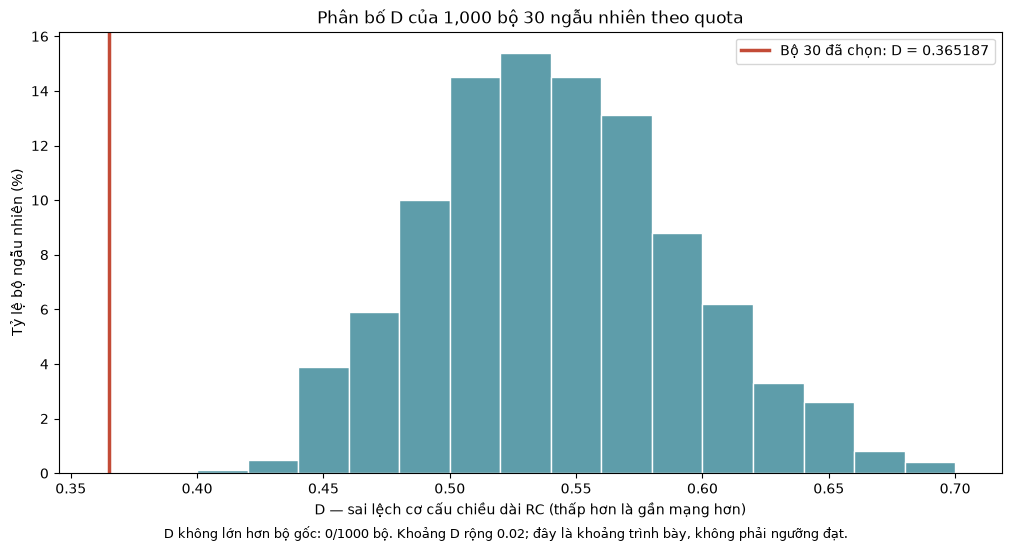

In [6]:
histogram = plots.plot_d_histogram(data, bin_width=BIN_WIDTH, stat=HIST_STAT)
display(histogram)
plt.close(histogram)

### 6. Hình quan hệ D với độ phủ hoặc chiều dài

Mỗi chấm là một bộ 30 ngẫu nhiên; ngôi sao là bộ đã chọn. Đường hồi quy chỉ khớp trên M0, không dùng ngôi sao. Trục độ phủ hiển thị **% mạng RC không trùng**; chiều dài hiển thị **km lượt đi**.

R² chỉ mô tả mối liên hệ trong mô phỏng, không chứng minh nhân quả hay tính đại diện thực địa. Không dùng số thứ tự lần bốc làm biến giải thích.

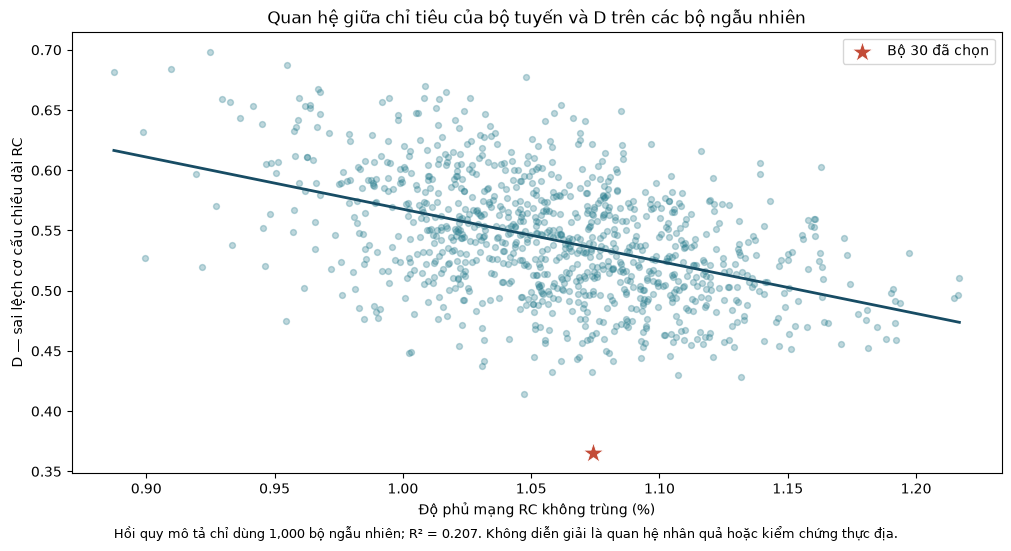

Trạng thái khớp: fitted | Số bộ dùng khớp: 1000
Hệ số góc: -0.43307182008437095 | Đơn vị X: percentage_point
Hệ số chặn: 1.000750719337226 | R² mô tả: 0.2065687211606253
X bộ gốc nằm trong khoảng X của M0: True


In [7]:
relationship = plots.plot_d_relationship(data, x_metric=X_METRIC, fit_line=FIT_LINE)
display(relationship)
plt.close(relationship)
fit = plots.regression_summary(data, X_METRIC)
print("Trạng thái khớp:", fit["status"], "| Số bộ dùng khớp:", fit["n"])
if FIT_LINE and fit["status"] == "fitted":
    print("Hệ số góc:", fit["slope"], "| Đơn vị X:", fit["x_unit"])
    print("Hệ số chặn:", fit["intercept"], "| R² mô tả:", fit["r_squared"])
print("X bộ gốc nằm trong khoảng X của M0:", fit["baseline_within_random_x_range"])

### 7. Xuất hình và bảng

Lưu PNG 240 dpi, SVG, toàn bộ bảng khoảng D và báo cáo truy vết dưới `work/reports/selection/plots/<hash>/`. Không ghi vào bundle M0 hay bản công bố. Nếu vừa đổi nguồn/tham số, phải vẽ lại trước khi xuất.

In [8]:
directory, plot_report = plots.export_comparison(
    data, histogram, relationship,
    bin_width=BIN_WIDTH, stat=HIST_STAT, x_metric=X_METRIC, fit_line=FIT_LINE,
)
print("Thư mục xuất:", "work/" + directory.relative_to(WORK).as_posix())
for name in sorted(p.name for p in directory.iterdir() if p.is_file()):
    print("-", name)
print("Bốc lại M0:", plot_report["random_sampling_rerun"])

Thư mục xuất: work/reports/selection/plots/2d2329af630cebea5d5a
- D_histogram.png
- D_histogram.svg
- D_intervals.csv
- D_relationship.png
- D_relationship.svg
- manifest.json
- plot_report.json
Bốc lại M0: False


### Đọc kết quả đúng phạm vi

Quan sát 0/1.000 bộ có D không lớn hơn bộ gốc không có nghĩa p-value hoặc xác suất thật bằng 0. Bộ gốc đã được tối ưu trên cùng pool; hình không chứng minh tối ưu toàn cục. Các bộ độc lập được phép lặp thành phần giữa các lần bốc; không tự bỏ trùng.

Kết quả vẫn là tiền khảo sát. Quyền lưu thông, G1/G4/G5/G6, C6 thực địa và ô A × RC1 không được xác nhận bằng hai biểu đồ này. Dữ liệu nền: © OpenStreetMap contributors, theo [ODbL](https://opendatacommons.org/licenses/odbl/1-0/).